In [1]:
from pathlib import Path

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Load cleaned dataset
DATA_PATH = Path("../processed/cleaned_car_data.csv")

df = pd.read_csv(DATA_PATH)

# Display configuration
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 120)

sns.set_theme(style="whitegrid")

print("Dataset shape:", df.shape)

display(df.head())

print("\nDataset information:")
df.info()

print("\nStatistical summary:")
display(df.describe().T)

print("\nMissing values:")
display(
    df.isnull().sum()
    .to_frame("Missing Values")
    .query("`Missing Values` > 0")
)

Dataset shape: (6926, 19)


,name,year,selling_price,km_driven,fuel,seller_type,transmission,owner,mileage,engine,max_power,torque,seats,mileage_value,mileage_unit,engine_cc,max_power_bhp,torque_nm,car_age
0,Maruti Swift Dzire VDI,2014,450000,145500,Diesel,Individual,Manual,First Owner,23.4 kmpl,1248 CC,74 bhp,190Nm@ 2000rpm,5.0,23.40,kmpl,1248.0,74.00,190.000000,6
1,Skoda Rapid 1.5 TDI Ambition,2014,370000,120000,Diesel,Individual,Manual,Second Owner,21.14 kmpl,1498 CC,103.52 bhp,250Nm@ 1500-2500rpm,5.0,21.14,kmpl,1498.0,103.52,250.000000,6
2,Honda City 2017-2020 EXi,2006,158000,140000,Petrol,Individual,Manual,Third Owner,17.7 kmpl,1497 CC,78 bhp,"12.7@ 2,700(kgm@ rpm)",5.0,17.70,kmpl,1497.0,78.00,124.544455,14
3,Hyundai i20 Sportz Diesel,2010,225000,127000,Diesel,Individual,Manual,First Owner,23.0 kmpl,1396 CC,90 bhp,22.4 kgm at 1750-2750rpm,5.0,23.00,kmpl,1396.0,90.00,219.668960,10
4,Maruti Swift VXI BSIII,2007,130000,120000,Petrol,Individual,Manual,First Owner,16.1 kmpl,1298 CC,88.2 bhp,"11.5@ 4,500(kgm@ rpm)",5.0,16.10,kmpl,1298.0,88.20,112.776475,13



Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 6926 entries, 0 to 6925
Data columns (total 19 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   name           6926 non-null   str    
 1   year           6926 non-null   int64  
 2   selling_price  6926 non-null   int64  
 3   km_driven      6926 non-null   int64  
 4   fuel           6926 non-null   str    
 5   seller_type    6926 non-null   str    
 6   transmission   6926 non-null   str    
 7   owner          6926 non-null   str    
 8   mileage        6718 non-null   str    
 9   engine         6718 non-null   str    
 10  max_power      6721 non-null   str    
 11  torque         6717 non-null   str    
 12  seats          6718 non-null   float64
 13  mileage_value  6718 non-null   float64
 14  mileage_unit   6718 non-null   str    
 15  engine_cc      6718 non-null   float64
 16  max_power_bhp  6720 non-null   float64
 17  torque_nm      6707 non-null   float64
 1

,count,mean,std,min,25%,50%,75%,max
year,6926.0,2013.420300,4.078286,1983.00000,2011.0,2014.00,2017.00000,2.020000e+03
selling_price,6926.0,517270.678458,519766.985985,29999.00000,250000.0,400000.00,633500.00000,1.000000e+07
km_driven,6926.0,73995.676437,58358.095175,1.00000,40000.0,70000.00,100000.00000,2.360457e+06
seats,6718.0,5.434653,0.984230,2.00000,5.0,5.00,5.00000,1.400000e+01
mileage_value,6718.0,19.465310,4.049150,0.00000,16.8,19.44,22.50000,4.200000e+01
engine_cc,6718.0,1430.891337,493.493277,624.00000,1197.0,1248.00,1498.00000,3.604000e+03
max_power_bhp,6720.0,87.726919,31.771619,0.00000,67.1,81.83,100.00000,4.000000e+02
torque_nm,6707.0,175.095107,115.303129,47.07192,110.0,160.00,200.05566,3.726527e+03
car_age,6926.0,6.579700,4.078286,0.00000,3.0,6.00,9.00000,3.700000e+01



Missing values:


,Missing Values
mileage,208
engine,208
max_power,205
torque,209
seats,208
mileage_value,208
mileage_unit,208
engine_cc,208
max_power_bhp,206
torque_nm,219


In [2]:
# Exploratory Data Analysis (EDA)

## 1. Selling Price Distribution

The selling price is our target variable. We examine its distribution
to understand the typical price range, spread and presence of unusually
high-priced vehicles.

SyntaxError: invalid syntax (447696692.py, line 5)

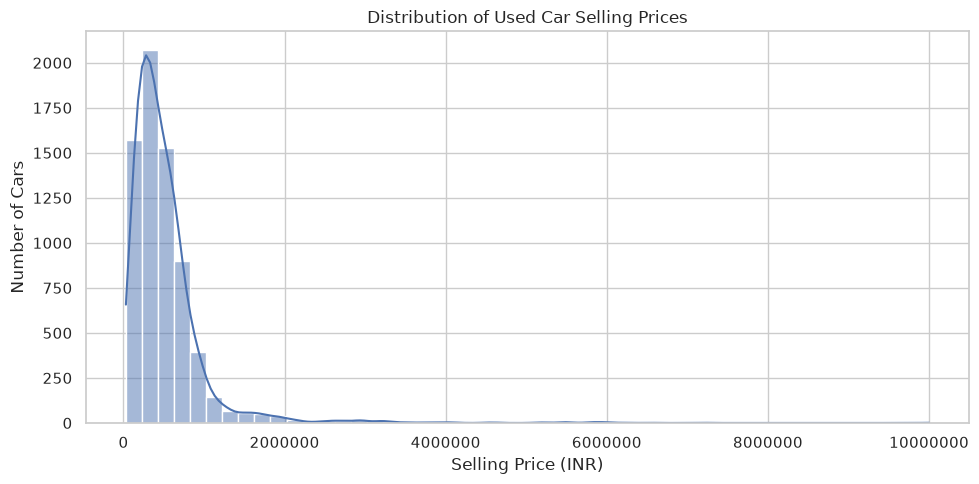

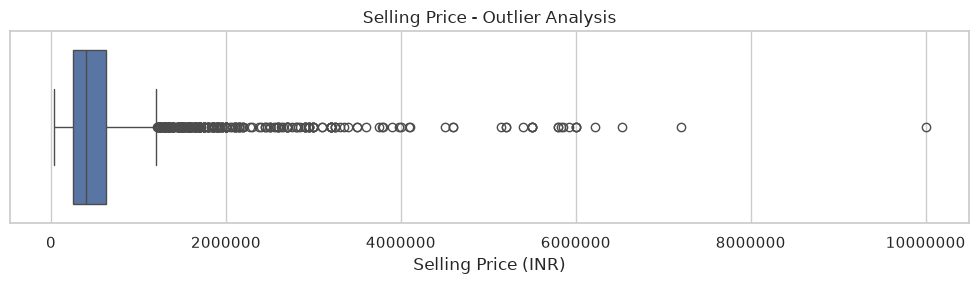

Selling Price Statistics:


count    6.926000e+03
mean     5.172707e+05
std      5.197670e+05
min      2.999900e+04
25%      2.500000e+05
50%      4.000000e+05
75%      6.335000e+05
max      1.000000e+07
Name: selling_price, dtype: float64


Median selling price: ₹400,000
Mean selling price: ₹517,271


In [3]:
# Selling price distribution

plt.figure(figsize=(10, 5))

sns.histplot(
    data=df,
    x="selling_price",
    bins=50,
    kde=True
)

plt.title("Distribution of Used Car Selling Prices")
plt.xlabel("Selling Price (INR)")
plt.ylabel("Number of Cars")
plt.ticklabel_format(style="plain", axis="x")
plt.tight_layout()
plt.show()


# Boxplot to identify potential outliers

plt.figure(figsize=(10, 3))

sns.boxplot(x=df["selling_price"])

plt.title("Selling Price - Outlier Analysis")
plt.xlabel("Selling Price (INR)")
plt.ticklabel_format(style="plain", axis="x")
plt.tight_layout()
plt.show()


# Numerical summary

print("Selling Price Statistics:")
display(df["selling_price"].describe())

print(
    "\nMedian selling price:",
    f"₹{df['selling_price'].median():,.0f}"
)

print(
    "Mean selling price:",
    f"₹{df['selling_price'].mean():,.0f}"
)

In [4]:
## 2. Relationship Between Car Age and Selling Price

We investigate whether the age of a vehicle is associated with
its resale value.

SyntaxError: invalid syntax (2259139547.py, line 3)

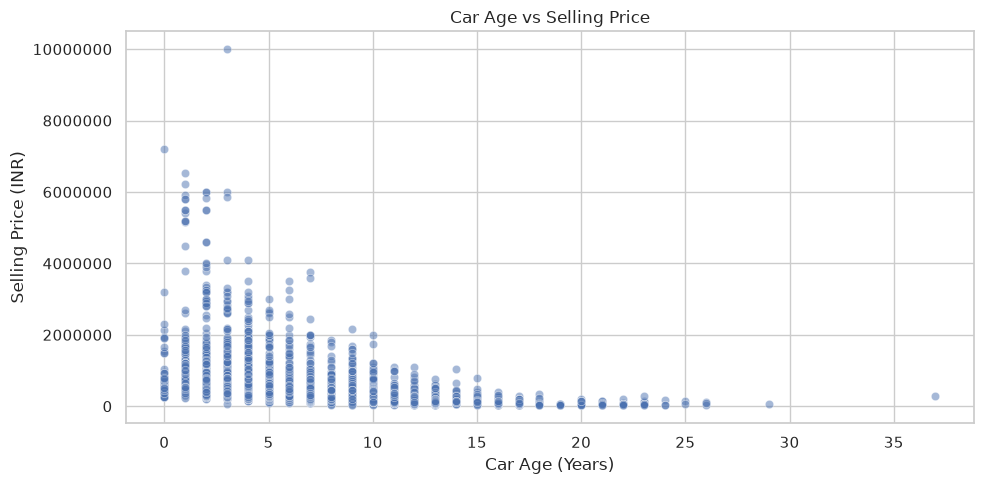

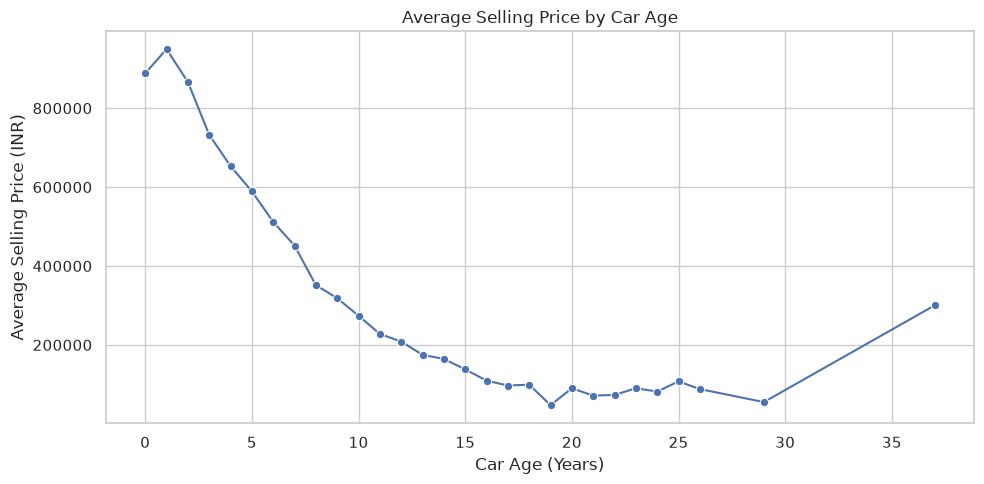

,car_age,selling_price
0,0,888349.158730
1,1,949668.547550
2,2,866376.613487
3,3,732419.517327
4,4,653180.339105
5,5,589177.625551
6,6,511858.798623
7,7,451501.724199
8,8,351387.379139
9,9,318335.696751


In [5]:
# Car age vs selling price

plt.figure(figsize=(10, 5))

sns.scatterplot(
    data=df,
    x="car_age",
    y="selling_price",
    alpha=0.5
)

plt.title("Car Age vs Selling Price")
plt.xlabel("Car Age (Years)")
plt.ylabel("Selling Price (INR)")
plt.ticklabel_format(style="plain", axis="y")
plt.tight_layout()
plt.show()


# Average selling price by car age

age_price = (
    df.groupby("car_age")["selling_price"]
    .mean()
    .reset_index()
)

plt.figure(figsize=(10, 5))

sns.lineplot(
    data=age_price,
    x="car_age",
    y="selling_price",
    marker="o"
)

plt.title("Average Selling Price by Car Age")
plt.xlabel("Car Age (Years)")
plt.ylabel("Average Selling Price (INR)")
plt.ticklabel_format(style="plain", axis="y")
plt.tight_layout()
plt.show()


display(age_price)

In [6]:
## 3. Relationship Between Kilometres Driven and Selling Price

We examine whether vehicles with higher usage tend to have
lower resale prices.
    

SyntaxError: invalid syntax (2635626614.py, line 3)

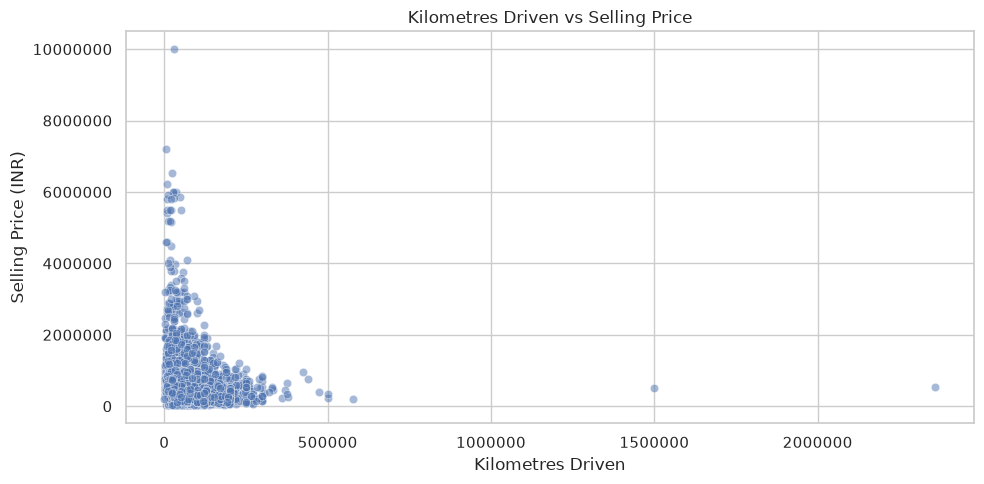

Correlation with Selling Price:


,Correlation
selling_price,1.000000
max_power_bhp,0.691536
torque_nm,0.442961
engine_cc,0.442857
year,0.433076
seats,0.158111
mileage_value,-0.108344
km_driven,-0.165620
car_age,-0.433076


In [7]:
# Kilometres driven vs selling price

plt.figure(figsize=(10, 5))

sns.scatterplot(
    data=df,
    x="km_driven",
    y="selling_price",
    alpha=0.5
)

plt.title("Kilometres Driven vs Selling Price")
plt.xlabel("Kilometres Driven")
plt.ylabel("Selling Price (INR)")
plt.ticklabel_format(style="plain", axis="both")
plt.tight_layout()
plt.show()


# Correlation between numeric features

print("Correlation with Selling Price:")

correlation = (
    df.select_dtypes(include="number")
    .corr()["selling_price"]
    .sort_values(ascending=False)
)

display(correlation.to_frame("Correlation"))

In [8]:
## 4. Categorical Features vs Selling Price

We compare selling prices across different fuel types, transmission
types, seller categories and ownership groups to identify patterns
in the used-car market.

SyntaxError: invalid syntax (691298312.py, line 3)

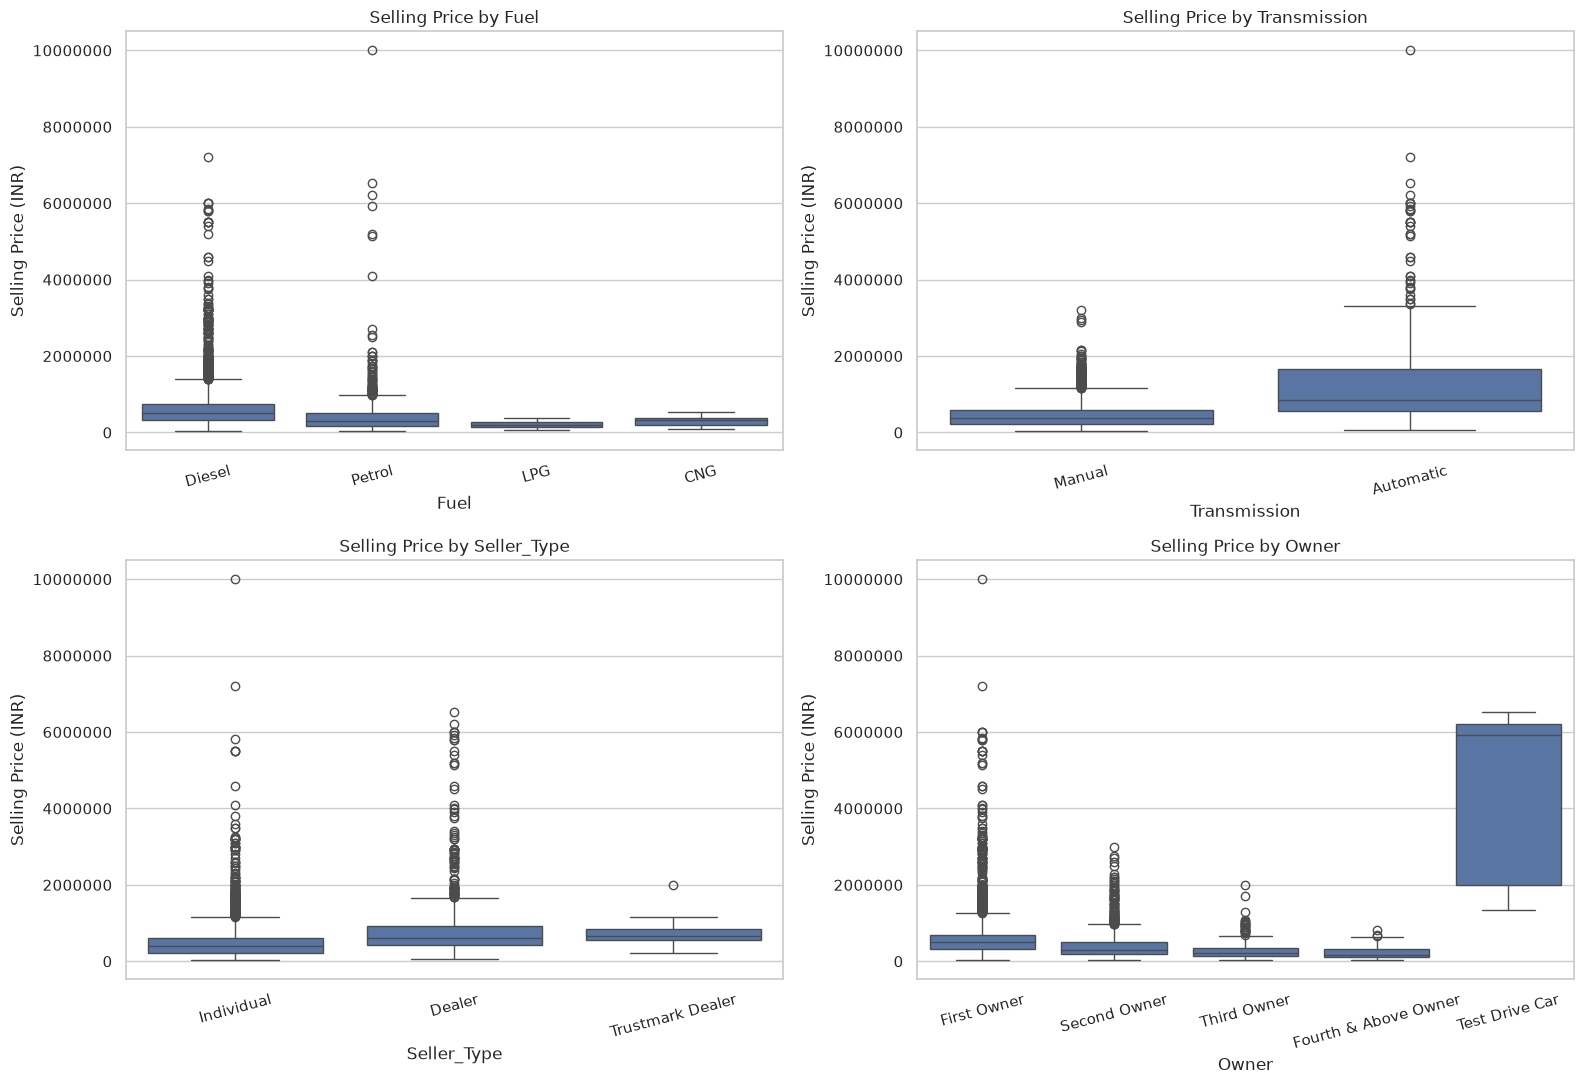

In [9]:
# Categorical features to analyse
categorical_columns = [
    "fuel",
    "transmission",
    "seller_type",
    "owner"
]

# Plot selling price distributions by category
fig, axes = plt.subplots(2, 2, figsize=(16, 11))

for column, ax in zip(categorical_columns, axes.flatten()):

    sns.boxplot(
        data=df,
        x=column,
        y="selling_price",
        ax=ax
    )

    ax.set_title(f"Selling Price by {column.title()}")
    ax.set_xlabel(column.title())
    ax.set_ylabel("Selling Price (INR)")
    ax.tick_params(axis="x", rotation=15)
    ax.ticklabel_format(style="plain", axis="y")

plt.tight_layout()
plt.show()

In [10]:
# Average selling price for each categorical feature

for column in categorical_columns:

    summary = (
        df.groupby(column)["selling_price"]
        .agg(["count", "mean", "median"])
        .sort_values("mean", ascending=False)
    )

    print(f"\nSelling Price Analysis by {column.upper()}")
    display(summary.round(2))


Selling Price Analysis by FUEL


,count,mean,median
fuel,,,
Diesel,3755,639727.77,520000.0
Petrol,3077,375688.97,310000.0
CNG,56,300499.95,320000.0
LPG,38,200421.05,195500.0



Selling Price Analysis by TRANSMISSION


,count,mean,median
transmission,,,
Automatic,584,1309712.30,850000.0
Manual,6342,444299.07,385000.0



Selling Price Analysis by SELLER_TYPE


,count,mean,median
seller_type,,,
Dealer,681,926722.42,620000.0
Trustmark Dealer,27,718111.11,650000.0
Individual,6218,471555.12,390000.0



Selling Price Analysis by OWNER


,count,mean,median
owner,,,
Test Drive Car,5,4403800.00,5923000.0
First Owner,4242,615404.40,500000.0
Second Owner,1974,385697.19,305000.0
Third Owner,536,281250.95,222500.0
Fourth & Above Owner,169,224470.37,170000.0


In [11]:
## 5. Correlation Analysis

We use a correlation heatmap to examine relationships between
numerical vehicle features and selling price.

SyntaxError: invalid syntax (436964735.py, line 3)

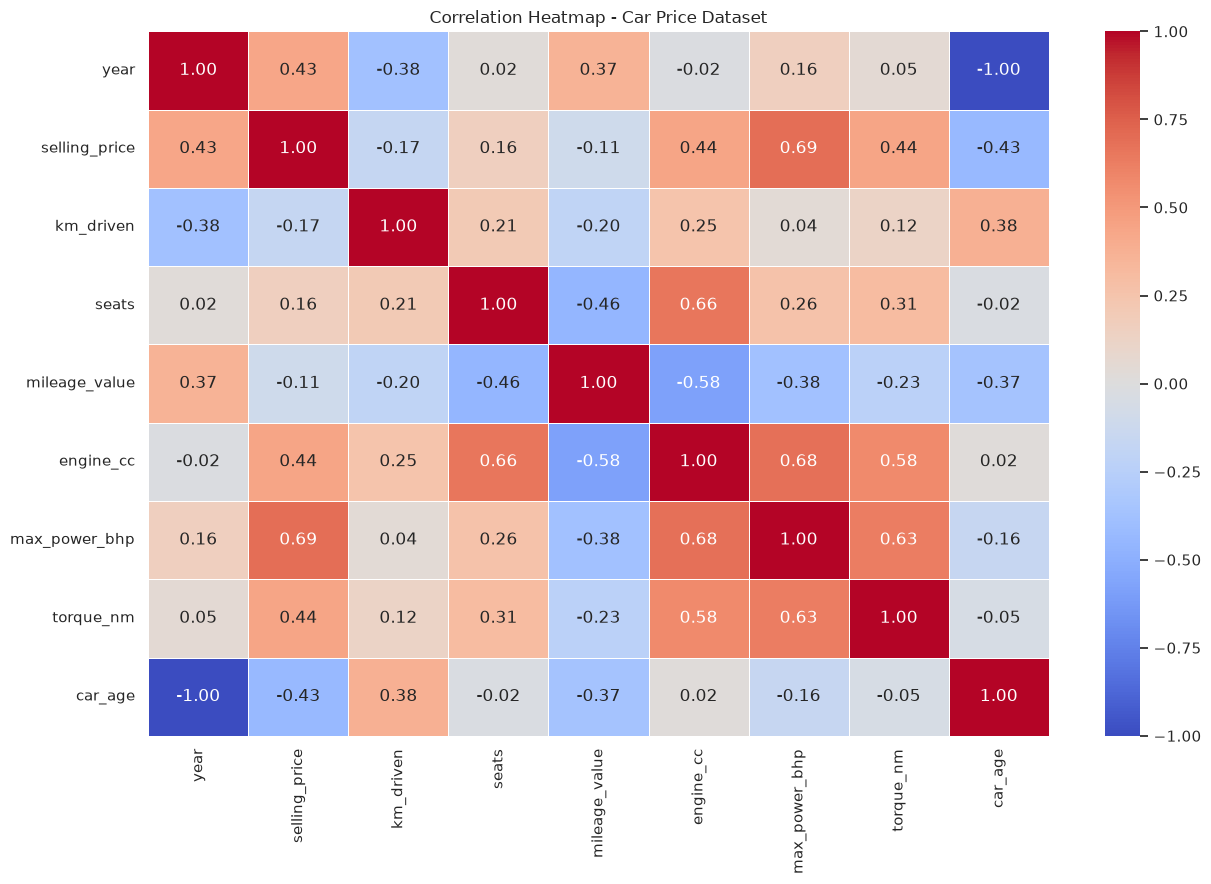

In [12]:
# Select numerical columns
numeric_df = df.select_dtypes(include="number")

# Calculate correlations
correlation_matrix = numeric_df.corr()

# Plot heatmap
plt.figure(figsize=(13, 9))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5
)

plt.title("Correlation Heatmap - Car Price Dataset")
plt.tight_layout()
plt.show()

In [13]:
## 6. Feature Engineering and Selection

We extract the vehicle manufacturer from the car name and select
relevant numerical and categorical features for regression.

The selling price is treated as the target variable. Raw specification
columns are excluded because their numeric values have already been
extracted into engineered features.

SyntaxError: invalid syntax (1146286977.py, line 3)

In [14]:
# Create a separate modelling dataset
model_df = df.copy()

# Extract the first word of the car name as a manufacturer category
model_df["brand"] = (
    model_df["name"]
    .str.strip()
    .str.split()
    .str[0]
    .str.title()
)

# Select numerical and categorical features
feature_columns = [
    "brand",
    "car_age",
    "km_driven",
    "mileage_value",
    "mileage_unit",
    "engine_cc",
    "max_power_bhp",
    "torque_nm",
    "seats",
    "fuel",
    "transmission",
    "seller_type",
    "owner"
]

target_column = "selling_price"

X = model_df[feature_columns].copy()
y = model_df[target_column].copy()

print("Feature matrix shape:", X.shape)
print("Target shape:", y.shape)

print("\nSelected features:")
print(X.columns.tolist())

print("\nFeature data types:")
display(X.dtypes.to_frame("Data Type"))

print("\nMissing values in selected features:")
display(
    X.isnull().sum()
    .to_frame("Missing Values")
    .query("`Missing Values` > 0")
)

print("\nManufacturer categories:")
print("Unique brands:", X["brand"].nunique())
display(X["brand"].value_counts().head(15).to_frame("Car Count"))

print("\nTarget variable:")
display(y.describe())

Feature matrix shape: (6926, 13)
Target shape: (6926,)

Selected features:
['brand', 'car_age', 'km_driven', 'mileage_value', 'mileage_unit', 'engine_cc', 'max_power_bhp', 'torque_nm', 'seats', 'fuel', 'transmission', 'seller_type', 'owner']

Feature data types:


,Data Type
brand,object
car_age,int64
km_driven,int64
mileage_value,float64
mileage_unit,str
engine_cc,float64
max_power_bhp,float64
torque_nm,float64
seats,float64
fuel,str



Missing values in selected features:


,Missing Values
mileage_value,208
mileage_unit,208
engine_cc,208
max_power_bhp,206
torque_nm,219
seats,208



Manufacturer categories:
Unique brands: 32


,Car Count
brand,
Maruti,2165
Hyundai,1267
Mahindra,723
Tata,647
Honda,362
Ford,361
Toyota,357
Chevrolet,216
Renault,206



Target variable:


count    6.926000e+03
mean     5.172707e+05
std      5.197670e+05
min      2.999900e+04
25%      2.500000e+05
50%      4.000000e+05
75%      6.335000e+05
max      1.000000e+07
Name: selling_price, dtype: float64

In [15]:
## 7. Train-Test Split

We divide the dataset into training and testing subsets.

- 80% of records are used for model training.
- 20% are reserved for final evaluation.
- Random state 42 ensures reproducibility.

The test data will remain unseen during model training.

SyntaxError: invalid syntax (3280598334.py, line 3)

In [16]:
from sklearn.model_selection import train_test_split

# Split features and target
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("Training feature shape:", X_train.shape)
print("Testing feature shape:", X_test.shape)

print("Training target shape:", y_train.shape)
print("Testing target shape:", y_test.shape)

Training feature shape: (5540, 13)
Testing feature shape: (1386, 13)
Training target shape: (5540,)
Testing target shape: (1386,)


In [17]:
## 8. Model Building

We use two regression algorithms: Linear Regression and Random Forest.

Numerical features are median-imputed and standardized.
Categorical features are imputed using the most frequent category
and converted into numerical representations using One-Hot Encoding.

All preprocessing is fitted using training data only.

SyntaxError: invalid syntax (4014498381.py, line 3)

In [18]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor

# Identify numerical and categorical columns
numeric_features = X.select_dtypes(include="number").columns.tolist()
categorical_features = X.select_dtypes(exclude="number").columns.tolist()

print("Numerical features:", numeric_features)
print("\nCategorical features:", categorical_features)

# Numerical preprocessing
numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Categorical preprocessing
categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# Combine preprocessing
preprocessor = ColumnTransformer(transformers=[
    ("numeric", numeric_transformer, numeric_features),
    ("categorical", categorical_transformer, categorical_features)
])

# Define models
models = {
    "Linear Regression": LinearRegression(),

    "Random Forest": RandomForestRegressor(
        n_estimators=200,
        random_state=42,
        n_jobs=-1,
        min_samples_leaf=2
    )
}

# Create complete pipelines
model_pipelines = {}

for model_name, algorithm in models.items():

    model_pipelines[model_name] = Pipeline(steps=[
        ("preprocessor", preprocessor),
        ("regressor", algorithm)
    ])

print("\nPreprocessing and model pipelines created successfully.")

Numerical features: ['car_age', 'km_driven', 'mileage_value', 'engine_cc', 'max_power_bhp', 'torque_nm', 'seats']

Categorical features: ['brand', 'mileage_unit', 'fuel', 'transmission', 'seller_type', 'owner']

Preprocessing and model pipelines created successfully.


In [19]:
## 9. Model Training and Evaluation

Both regression models are trained using the training dataset.

We evaluate their predictions on the unseen test dataset using:

- MAE: Mean Absolute Error
- RMSE: Root Mean Squared Error
- R²: Coefficient of Determination

Lower MAE and RMSE indicate better prediction accuracy.
Higher R² indicates that the model explains more variation in selling prices.

SyntaxError: invalid character '²' (U+00B2) (1579270891.py, line 9)

In [20]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

results = []
trained_models = {}

for model_name, pipeline in model_pipelines.items():

    print(f"\nTraining {model_name}...")

    # Train
    pipeline.fit(X_train, y_train)

    # Predict on unseen test data
    predictions = pipeline.predict(X_test)

    # Calculate metrics
    mae = mean_absolute_error(y_test, predictions)
    rmse = np.sqrt(mean_squared_error(y_test, predictions))
    r2 = r2_score(y_test, predictions)

    results.append({
        "Model": model_name,
        "MAE": mae,
        "RMSE": rmse,
        "R2 Score": r2
    })

    trained_models[model_name] = pipeline

    print(f"MAE: ₹{mae:,.2f}")
    print(f"RMSE: ₹{rmse:,.2f}")
    print(f"R2 Score: {r2:.4f}")

# Comparison table
results_df = pd.DataFrame(results).sort_values("MAE")

print("\nMODEL COMPARISON")
display(results_df.round(4))


Training Linear Regression...
MAE: ₹132,937.49
RMSE: ₹261,730.89
R2 Score: 0.6877

Training Random Forest...
MAE: ₹70,780.51
RMSE: ₹116,786.50
R2 Score: 0.9378

MODEL COMPARISON


,Model,MAE,RMSE,R2 Score
1,Random Forest,70780.5145,116786.4976,0.9378
0,Linear Regression,132937.4934,261730.8923,0.6877


In [21]:
display(results_df.round(2))

,Model,MAE,RMSE,R2 Score
1,Random Forest,70780.51,116786.50,0.94
0,Linear Regression,132937.49,261730.89,0.69


In [22]:
display(results_df.round(2))

,Model,MAE,RMSE,R2 Score
1,Random Forest,70780.51,116786.50,0.94
0,Linear Regression,132937.49,261730.89,0.69


In [23]:
# Select the winning model
best_model = trained_models["Random Forest"]

# Generate predictions on unseen test data
y_pred = best_model.predict(X_test)

# Compare actual and predicted prices
prediction_comparison = pd.DataFrame({
    "Actual Price": y_test.values,
    "Predicted Price": y_pred.round(2),
})

prediction_comparison["Absolute Error"] = (
    prediction_comparison["Actual Price"]
    - prediction_comparison["Predicted Price"]
).abs().round(2)

display(prediction_comparison.head(15))

# Final validation metrics
print("Random Forest Validation")
print(f"MAE: ₹{mean_absolute_error(y_test, y_pred):,.2f}")
print(f"RMSE: ₹{np.sqrt(mean_squared_error(y_test, y_pred)):,.2f}")
print(f"R2 Score: {r2_score(y_test, y_pred):.4f}")

,Actual Price,Predicted Price,Absolute Error
0,550000,682709.83,132709.83
1,1225000,1081687.38,143312.62
2,850000,874245.24,24245.24
3,80000,129341.50,49341.50
4,825000,708214.74,116785.26
5,800000,934991.09,134991.09
6,229999,288753.29,58754.29
7,93150,218237.83,125087.83
8,300000,243448.54,56551.46
9,493000,536739.26,43739.26


Random Forest Validation
MAE: ₹70,780.51
RMSE: ₹116,786.50
R2 Score: 0.9378


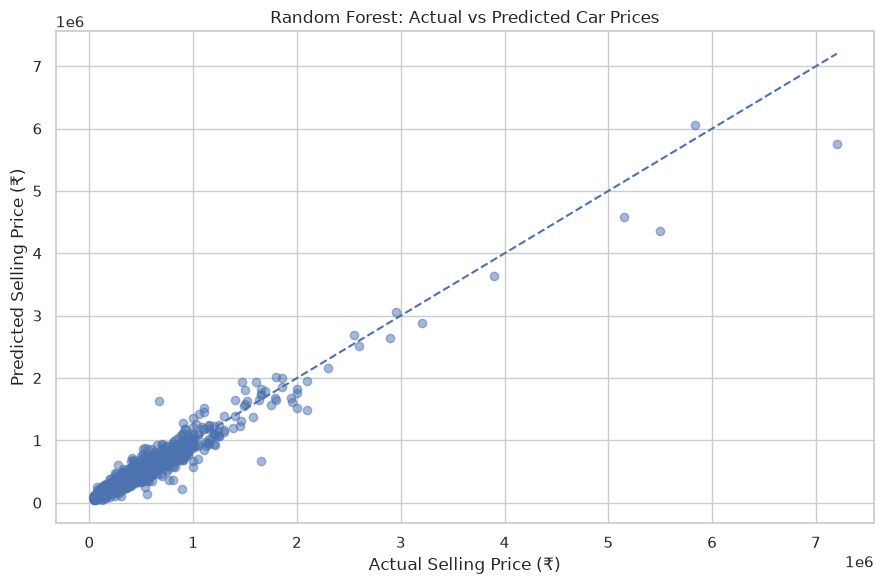

In [24]:
plt.figure(figsize=(9, 6))

plt.scatter(y_test, y_pred, alpha=0.5)

min_price = min(y_test.min(), y_pred.min())
max_price = max(y_test.max(), y_pred.max())

plt.plot(
    [min_price, max_price],
    [min_price, max_price],
    linestyle="--"
)

plt.xlabel("Actual Selling Price (₹)")
plt.ylabel("Predicted Selling Price (₹)")
plt.title("Random Forest: Actual vs Predicted Car Prices")
plt.tight_layout()
plt.show()

In [25]:
# Calculate prediction errors
error_analysis = prediction_comparison.copy()

error_analysis["Error Percentage"] = (
    error_analysis["Absolute Error"]
    / error_analysis["Actual Price"].replace(0, np.nan)
    * 100
).round(2)

# Summary of prediction errors
display(error_analysis["Absolute Error"].describe().to_frame())

print(
    "Predictions within ₹50,000:",
    (error_analysis["Absolute Error"] <= 50000).sum()
)

print(
    "Predictions within ₹1,00,000:",
    (error_analysis["Absolute Error"] <= 100000).sum()
)

# Display 10 predictions with the largest errors
display(
    error_analysis
    .sort_values("Absolute Error", ascending=False)
    .head(10)
)

,Absolute Error
count,1.386000e+03
mean,7.078051e+04
std,9.292704e+04
min,8.524000e+01
25%,2.013668e+04
50%,4.723646e+04
75%,8.987836e+04
max,1.455309e+06


Predictions within ₹50,000: 725
Predictions within ₹1,00,000: 1085


,Actual Price,Predicted Price,Absolute Error,Error Percentage
571,7200000,5744691.19,1455308.81,20.21
468,5500000,4351170.03,1148829.97,20.89
704,1650000,663581.45,986418.55,59.78
1364,667000,1634563.70,967563.70,145.06
525,890000,212751.66,677248.34,76.10
447,2100000,1489326.17,610673.83,29.08
112,5150000,4580223.62,569776.38,11.06
402,2000000,1516423.72,483576.28,24.18
1115,1465000,1931746.41,466746.41,31.86
1035,1000000,565144.64,434855.36,43.49


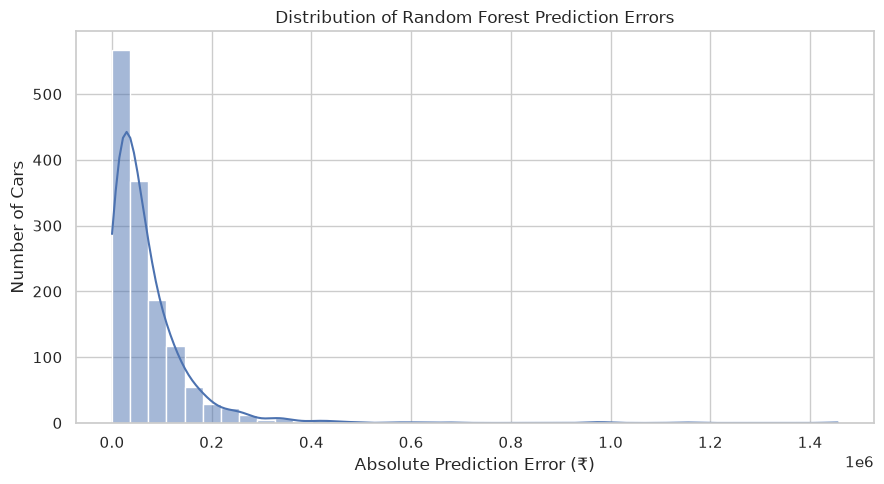

In [26]:
plt.figure(figsize=(9, 5))

sns.histplot(
    error_analysis["Absolute Error"],
    bins=40,
    kde=True
)

plt.xlabel("Absolute Prediction Error (₹)")
plt.ylabel("Number of Cars")
plt.title("Distribution of Random Forest Prediction Errors")
plt.tight_layout()
plt.show()

In [27]:
from pathlib import Path
import joblib

# Create models directory if it doesn't exist
MODEL_DIR = Path("../models")
MODEL_DIR.mkdir(parents=True, exist_ok=True)

# Save the complete trained pipeline
model_path = MODEL_DIR / "car_price_model.pkl"

joblib.dump(best_model, model_path)

print("Model saved successfully!")
print("Model location:", model_path.resolve())
print(f"Model size: {model_path.stat().st_size / 1024:.2f} KB")

Model saved successfully!
Model location: /home/kumar/DIRECTORIES/OIBSIP/DataScience-Task3-CarPricePrediction/models/car_price_model.pkl
Model size: 41960.39 KB


In [28]:
# Load the saved model
loaded_model = joblib.load(model_path)

# Predict using the loaded model
loaded_predictions = loaded_model.predict(X_test)

# Verify predictions
import numpy as np

print(
    "Predictions identical:",
    np.allclose(y_pred, loaded_predictions)
)

print("First 5 predictions:")

for actual, predicted in zip(y_test.head(5), loaded_predictions[:5]):
    print(
        f"Actual: ₹{actual:,.2f} | "
        f"Predicted: ₹{predicted:,.2f}"
    )

Predictions identical: True
First 5 predictions:
Actual: ₹550,000.00 | Predicted: ₹682,709.83
Actual: ₹1,225,000.00 | Predicted: ₹1,081,687.38
Actual: ₹850,000.00 | Predicted: ₹874,245.24
Actual: ₹80,000.00 | Predicted: ₹129,341.50
Actual: ₹825,000.00 | Predicted: ₹708,214.74


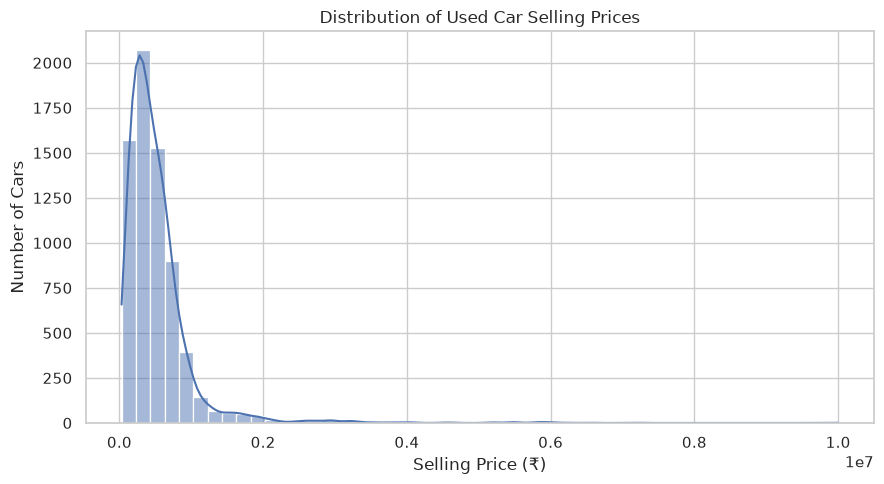

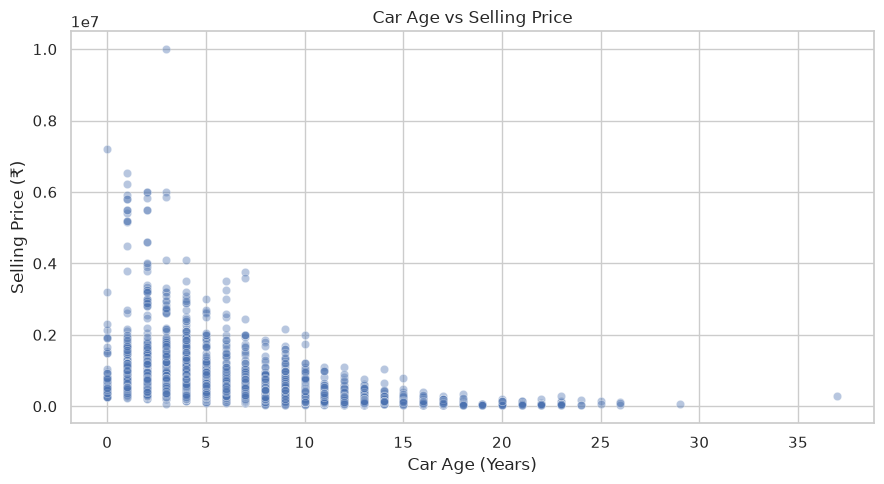

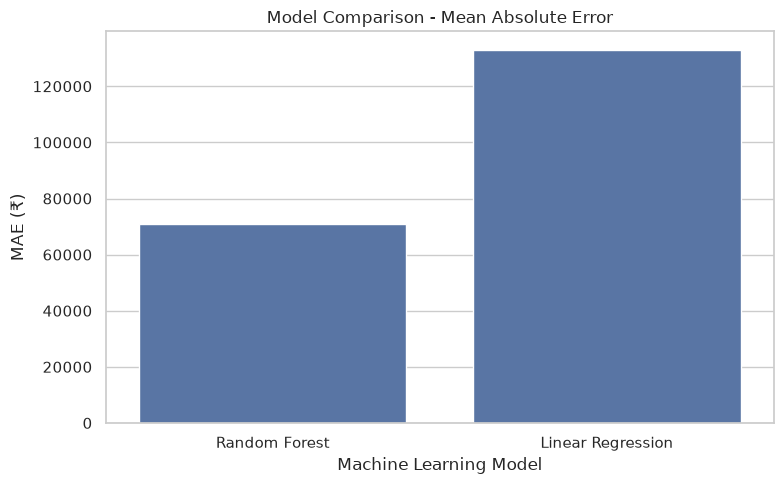

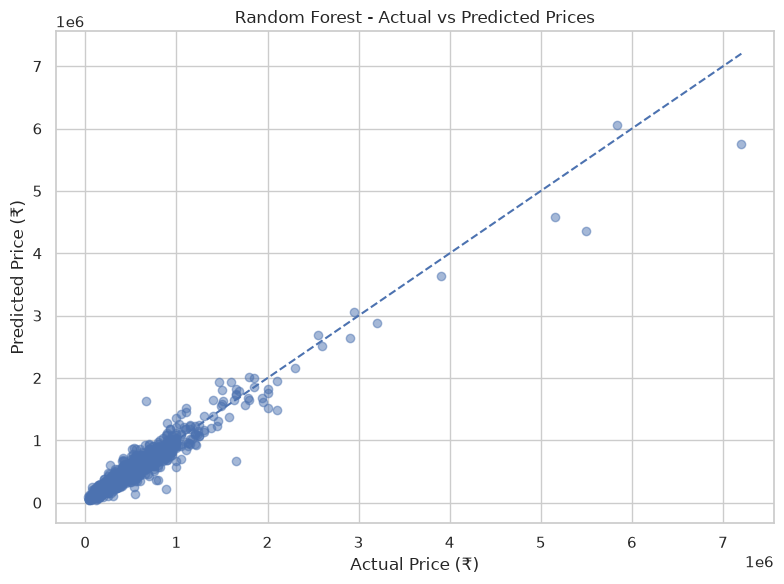

All visualization images saved successfully.


In [29]:
from pathlib import Path
import matplotlib.pyplot as plt
import seaborn as sns

SCREENSHOT_DIR = Path("../screenshots")
SCREENSHOT_DIR.mkdir(parents=True, exist_ok=True)

# 1. Selling price distribution
plt.figure(figsize=(9, 5))
sns.histplot(df["selling_price"], bins=50, kde=True)
plt.title("Distribution of Used Car Selling Prices")
plt.xlabel("Selling Price (₹)")
plt.ylabel("Number of Cars")
plt.tight_layout()
plt.savefig(SCREENSHOT_DIR / "01_price_distribution.png", dpi=150)
plt.show()

# 2. Car age vs selling price
plt.figure(figsize=(9, 5))
sns.scatterplot(
    data=df,
    x="car_age",
    y="selling_price",
    alpha=0.4
)
plt.title("Car Age vs Selling Price")
plt.xlabel("Car Age (Years)")
plt.ylabel("Selling Price (₹)")
plt.tight_layout()
plt.savefig(SCREENSHOT_DIR / "02_car_age_vs_price.png", dpi=150)
plt.show()

# 3. Model comparison
plt.figure(figsize=(8, 5))
sns.barplot(data=results_df, x="Model", y="MAE")
plt.title("Model Comparison - Mean Absolute Error")
plt.xlabel("Machine Learning Model")
plt.ylabel("MAE (₹)")
plt.tight_layout()
plt.savefig(SCREENSHOT_DIR / "03_model_comparison.png", dpi=150)
plt.show()

# 4. Actual vs predicted prices
plt.figure(figsize=(8, 6))
plt.scatter(y_test, y_pred, alpha=0.5)

min_price = min(y_test.min(), y_pred.min())
max_price = max(y_test.max(), y_pred.max())

plt.plot(
    [min_price, max_price],
    [min_price, max_price],
    linestyle="--"
)

plt.title("Random Forest - Actual vs Predicted Prices")
plt.xlabel("Actual Price (₹)")
plt.ylabel("Predicted Price (₹)")
plt.tight_layout()
plt.savefig(SCREENSHOT_DIR / "04_actual_vs_predicted.png", dpi=150)
plt.show()

print("All visualization images saved successfully.")